In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
import ast
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
folder = r"C:\Users\Icon\OneDrive\Desktop\Internship"

files = glob.glob(os.path.join(folder, "ted_talks_features*"))

if not files:
    files = glob.glob(os.path.join(folder, "ted_talks_preprocessed*"))

if not files:
    raise FileNotFoundError("Dataset file not found!")

file_path = files[0]
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("File:", os.path.basename(file_path))
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
File: ted_talks_features.csv
Dataset Shape: (4005, 20)


,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript,combined_text
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre...",Averting the climate crisis ['alternative ener...
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac...","The best stats you've ever seen ['Africa', 'As..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun...","Simplicity sells ['computers', 'entertainment'..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...,"Greening the ghetto ['MacArthur grant', 'activ..."
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...,"Do schools kill creativity? ['children', 'crea..."


In [3]:
text_columns = [
    col for col in ["title", "topics", "description", "transcript"]
    if col in df.columns
]

if "combined_text" not in df.columns:
    df["combined_text"] = (
        df[text_columns]
        .fillna("")
        .astype(str)
        .agg(" ".join, axis=1)
    )

df["combined_text"] = (
    df["combined_text"]
    .fillna("")
    .astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

def extract_topics(value):
    if pd.isna(value):
        return set()

    value = str(value)

    try:
        parsed = ast.literal_eval(value)
        if isinstance(parsed, (list, tuple, set)):
            return {
                str(x).strip().lower()
                for x in parsed if str(x).strip()
            }
    except (ValueError, SyntaxError):
        pass

    return {
        x.strip().lower()
        for x in re.split(r"[,;|]", value.strip("[]"))
        if x.strip()
    }

if "topics" not in df.columns:
    raise ValueError("Topics column not found!")

df["topic_set"] = df["topics"].apply(extract_topics)

df = df[
    (df["combined_text"] != "") &
    (df["topic_set"].apply(len) > 0)
].reset_index(drop=True)

print("Prepared Dataset:", df.shape)

Prepared Dataset: (4005, 21)


In [4]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training Records:", len(train_df))
print("Testing Records:", len(test_df))

Training Records: 3204
Testing Records: 801


In [5]:
tfidf = TfidfVectorizer(
    max_features=20000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

train_vectors = tfidf.fit_transform(train_df["combined_text"])
test_vectors = tfidf.transform(test_df["combined_text"])

print("TF-IDF Vectorization Completed!")
print("Training Vector Shape:", train_vectors.shape)
print("Testing Vector Shape:", test_vectors.shape)

TF-IDF Vectorization Completed!
Training Vector Shape: (3204, 20000)
Testing Vector Shape: (801, 20000)


In [6]:
similarity_scores = cosine_similarity(
    test_vectors,
    train_vectors
)

if "views" in train_df.columns:
    train_views = pd.to_numeric(
        train_df["views"], errors="coerce"
    ).fillna(0).to_numpy()
else:
    train_views = np.zeros(len(train_df))

popularity_ranking = np.argsort(-train_views)

print("Similarity Scores Calculated!")

Similarity Scores Calculated!


In [7]:
def precision_at_k(relevance, k):
    return np.sum(relevance[:k]) / k


def recall_at_k(relevance, total_relevant, k):
    if total_relevant == 0:
        return 0
    return np.sum(relevance[:k]) / total_relevant


def ndcg_at_k(relevance, total_relevant, k):
    relevance = np.asarray(relevance[:k], dtype=float)

    discounts = 1 / np.log2(np.arange(2, len(relevance) + 2))
    dcg = np.sum(relevance * discounts)

    ideal_length = min(total_relevant, k)
    ideal_relevance = np.ones(ideal_length)

    ideal_discounts = 1 / np.log2(
        np.arange(2, ideal_length + 2)
    )

    idcg = np.sum(ideal_relevance * ideal_discounts)

    return dcg / idcg if idcg > 0 else 0


def average_precision_at_k(relevance, total_relevant, k):
    relevance = np.asarray(relevance[:k])

    if total_relevant == 0:
        return 0

    precision_values = []
    relevant_count = 0

    for rank, value in enumerate(relevance, start=1):
        if value == 1:
            relevant_count += 1
            precision_values.append(relevant_count / rank)

    if not precision_values:
        return 0

    return sum(precision_values) / min(total_relevant, k)


print("All Evaluation Metrics Functions Ready!")

All Evaluation Metrics Functions Ready!


In [8]:
K_VALUES = [5, 10]

results = []
evaluated_queries = 0

for query_index in range(len(test_df)):

    query_topics = test_df.loc[query_index, "topic_set"]

    relevance_all = np.array([
        int(len(query_topics.intersection(candidate_topics)) > 0)
        for candidate_topics in train_df["topic_set"]
    ])

    total_relevant = int(relevance_all.sum())

    if total_relevant == 0:
        continue

    evaluated_queries += 1

    content_order = np.argsort(
        -similarity_scores[query_index]
    )

    models = {
        "Content-Based": content_order,
        "Popularity Baseline": popularity_ranking
    }

    for model_name, ranking in models.items():

        ranked_relevance = relevance_all[ranking]

        for k in K_VALUES:

            results.append({
                "Model": model_name,
                "K": k,
                "Precision": precision_at_k(ranked_relevance, k),
                "Recall": recall_at_k(ranked_relevance, total_relevant, k),
                "NDCG": ndcg_at_k(ranked_relevance, total_relevant, k),
                "MAP": average_precision_at_k(
                    ranked_relevance, total_relevant, k
                )
            })

results_df = pd.DataFrame(results)

print("Evaluation Completed!")
print("Evaluated Queries:", evaluated_queries)
print("Skipped Queries:", len(test_df) - evaluated_queries)

display(results_df.head())

Evaluation Completed!
Evaluated Queries: 801
Skipped Queries: 0


,Model,K,Precision,Recall,NDCG,MAP
0,Content-Based,5,1.0,0.003193,1.000000,1.000000
1,Content-Based,10,0.9,0.005747,0.926636,0.866389
2,Popularity Baseline,5,0.2,0.000639,0.169580,0.066667
3,Popularity Baseline,10,0.1,0.000639,0.110046,0.033333
4,Content-Based,5,0.8,0.003325,0.830420,0.710000


In [9]:
comparison = (
    results_df
    .groupby(["Model", "K"])[
        ["Precision", "Recall", "NDCG", "MAP"]
    ]
    .mean()
    .reset_index()
)

print("MODEL PERFORMANCE COMPARISON")
display(comparison.round(4))

MODEL PERFORMANCE COMPARISON


,Model,K,Precision,Recall,NDCG,MAP
0,Content-Based,5,0.8874,0.0047,0.8946,0.8499
1,Content-Based,10,0.8679,0.0091,0.8787,0.8146
2,Popularity Baseline,5,0.3750,0.0016,0.3659,0.2462
3,Popularity Baseline,10,0.3095,0.0028,0.3231,0.1843


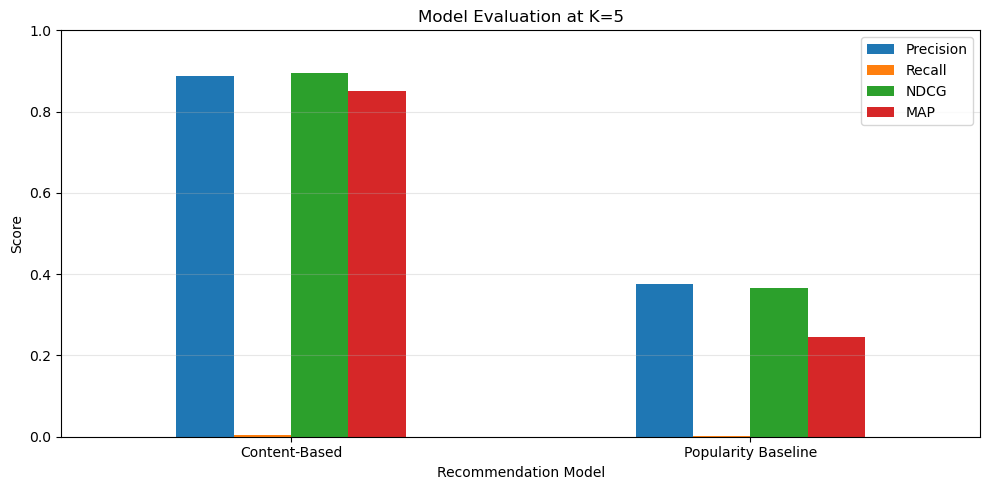

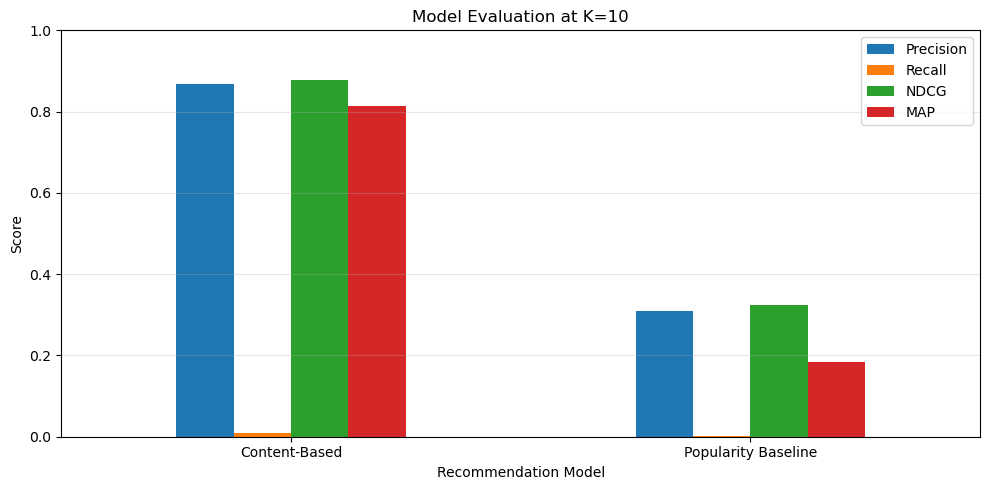

In [10]:
metrics = ["Precision", "Recall", "NDCG", "MAP"]

for k in K_VALUES:

    plot_data = comparison[
        comparison["K"] == k
    ].set_index("Model")

    plot_data[metrics].plot(
        kind="bar",
        figsize=(10, 5)
    )

    plt.title(f"Model Evaluation at K={k}")
    plt.xlabel("Recommendation Model")
    plt.ylabel("Score")
    plt.ylim(0, 1)
    plt.xticks(rotation=0)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

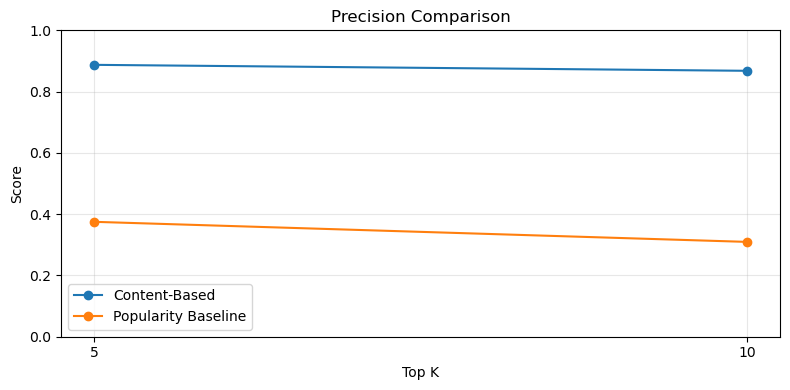

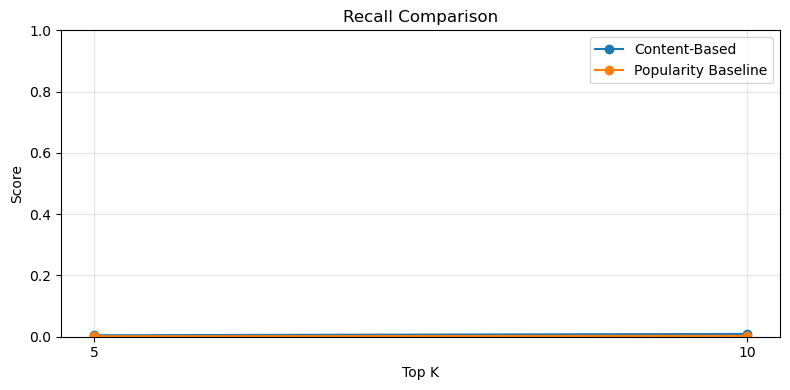

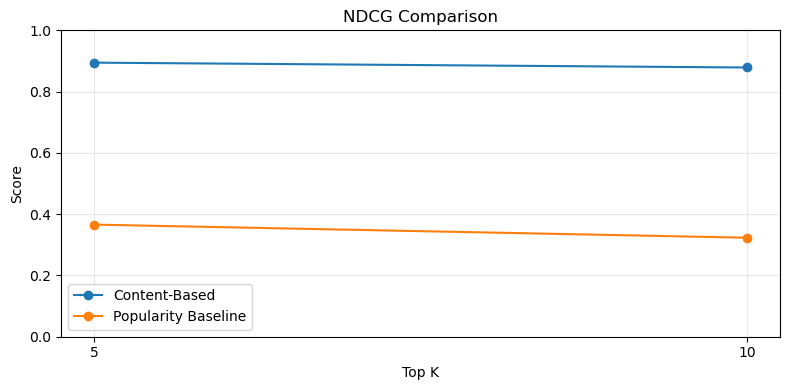

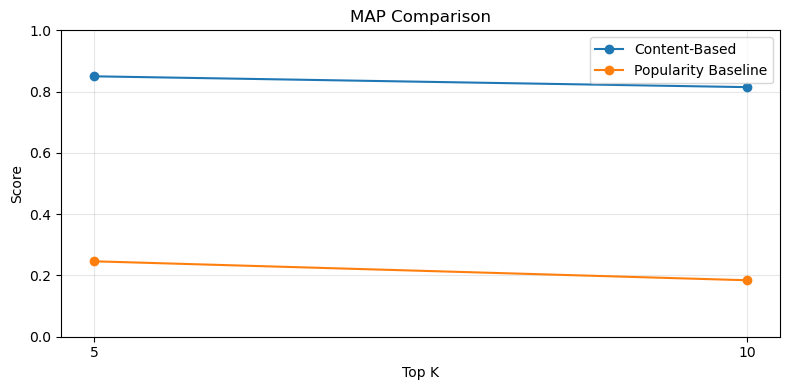

In [12]:
for metric in metrics:

    plt.figure(figsize=(8, 4))

    for model in comparison["Model"].unique():

        data = comparison[comparison["Model"] == model]

        plt.plot(
            data["K"],
            data[metric],
            marker="o",
            label=model
        )

    plt.title(metric + " Comparison")
    plt.xlabel("Top K")
    plt.ylabel("Score")
    plt.xticks(K_VALUES)
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [13]:
overall_scores = (
    comparison
    .groupby("Model")[metrics]
    .mean()
)

overall_scores["Average Score"] = overall_scores.mean(axis=1)

display(overall_scores.round(4))

best_model = overall_scores["Average Score"].idxmax()

print("Best Evaluated Model:", best_model)

,Precision,Recall,NDCG,MAP,Average Score
Model,,,,,
Content-Based,0.8777,0.0069,0.8866,0.8323,0.6509
Popularity Baseline,0.3423,0.0022,0.3445,0.2152,0.2261


Best Evaluated Model: Content-Based


In [14]:
comparison.to_csv(
    os.path.join(folder, "ted_evaluation_comparison.csv"),
    index=False
)

results_df.to_csv(
    os.path.join(folder, "ted_evaluation_detailed_results.csv"),
    index=False
)

overall_scores.to_csv(
    os.path.join(folder, "ted_model_performance_summary.csv")
)

print("Evaluation CSV files saved successfully!")

Evaluation CSV files saved successfully!


In [15]:
report = f"""
TED TALKS RECOMMENDATION SYSTEM
MODULE 5: EVALUATION REPORT

Dataset Records: {len(df)}
Training Records: {len(train_df)}
Testing Records: {len(test_df)}
Evaluated Queries: {evaluated_queries}

Evaluation Metrics:
1. Precision
2. Recall
3. NDCG
4. Mean Average Precision (MAP)

Models Compared:
1. Content-Based Filtering
2. Popularity Baseline

Best Evaluated Model: {best_model}

Relevance Method:
TED Talks with overlapping topics were considered relevant.

Limitation:
These are proxy evaluation results, not actual user satisfaction.
Collaborative Filtering and Hybrid Models were not evaluated
because genuine user interaction data was unavailable.

Final selection should also consider interpretability,
recommendation quality and real user feedback.
"""

with open(
    os.path.join(folder, "ted_evaluation_report.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(report)

print(report)
print("Final Evaluation Report Saved!")


TED TALKS RECOMMENDATION SYSTEM
MODULE 5: EVALUATION REPORT

Dataset Records: 4005
Training Records: 3204
Testing Records: 801
Evaluated Queries: 801

Evaluation Metrics:
1. Precision
2. Recall
3. NDCG
4. Mean Average Precision (MAP)

Models Compared:
1. Content-Based Filtering
2. Popularity Baseline

Best Evaluated Model: Content-Based

Relevance Method:
TED Talks with overlapping topics were considered relevant.

Limitation:
These are proxy evaluation results, not actual user satisfaction.
Collaborative Filtering and Hybrid Models were not evaluated
because genuine user interaction data was unavailable.

Final selection should also consider interpretability,
recommendation quality and real user feedback.

Final Evaluation Report Saved!
